In [ ]:
%pip install langchain-groq
%pip install langgraph
%pip install langchain
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [ ]:
from dotenv import load_dotenv

load_dotenv()

True

In [ ]:
llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0
)

In [ ]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [ ]:
def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [ ]:
checkpoint = MemorySaver()
graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)


chatbot = graph.compile(checkpointer=checkpoint)

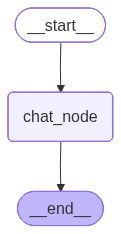

In [ ]:

chatbot

In [ ]:
thread_id = "2"


initial_state = {
    "messages": [
        HumanMessage(content="what is C++ and RAG")
    ]
}

config = {'configurable': {'thread_id': thread_id}}

response = chatbot.invoke(initial_state, config=config)

print(response["messages"][-1].content)

**What is C++?**

C++ is a high-performance, compiled, general-purpose programming language that was developed by Bjarne Stroustrup as an extension of the C programming language. It was first released in 1985 and has since become one of the most popular programming languages in the world.

C++ is known for its:

1. **Object-oriented programming (OOP) features**: C++ supports the principles of OOP, such as encapsulation, inheritance, and polymorphism, which make it easy to write reusable and maintainable code.
2. **Low-level memory management**: C++ allows developers to manually manage memory, which can be error-prone but also provides fine-grained control over system resources.
3. **Template metaprogramming**: C++'s template system allows developers to write generic code that can be instantiated at compile-time, which can lead to significant performance improvements.
4. **Multi-paradigm programming**: C++ supports multiple programming paradigms, including OOP, imperative programming, a

In [ ]:
response['messages'][-1].content

"Your name is Abhishek. We had a conversation about LangGraph earlier, and I'm happy to continue discussing it with you if you have any more questions or topics you'd like to explore."

In [ ]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='c86cd8c2-fb2f-4853-baf4-8c8c09deb84a'), AIMessage(content="I don't know your name. I'm a large language model, I don't have any information about you, including your name. I'm here to help answer your questions and provide information, but I don't have any personal knowledge about you. If you'd like to share your name, I'd be happy to chat with you!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 40, 'total_tokens': 109, 'completion_time': 0.171670029, 'completion_tokens_details': None, 'prompt_time': 0.001975235, 'prompt_tokens_details': None, 'queue_time': 0.052725235, 'total_time': 0.173645264}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f12dc-bee3-78d3-9a89-d9

In [ ]:
thread_id = "1"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config = config)
    print('AI:', response['messages'][-1].content)

User: what is my name
AI: Your name is Saurabh Kumar.
User: exit
